# Main Notebook for whole diabetes risk prediction 


In [2]:
# %pip install -q pandas numpy matplotlib seaborn scikit-learn joblib streamlit

In [6]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from preprocessing import (
    load_data,
    clean_data,
    split_data,
    fit_preprocessors,
    transform,
    save_split,
)          # our preprocessing pre-defined functions

sns.set_theme(style="whitegrid") 

In [7]:
# loading the Dataset via predefined methods
df_raw = load_data()
df_raw.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [8]:
df_raw.shape

(100000, 9)

#### 100k Rows with 9 Columns/Features. 
##### We would need different numbers of features for different models but the meaning and features would be same

In [9]:
dfRaw = df_raw

In [10]:
dfRaw.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  str    
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  str    
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 8.0 MB


In [11]:
dfRaw.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


In [14]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
gender,100000,3,Female,58552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,100000.0,NaN,NaN,NaN,41.885856,22.51684,0.08,24.0,43.0,60.0,80.0
hypertension,100000.0,NaN,NaN,NaN,0.07485,0.26315,0.0,0.0,0.0,0.0,1.0
heart_disease,100000.0,NaN,NaN,NaN,0.03942,0.194593,0.0,0.0,0.0,0.0,1.0
smoking_history,100000,6,No Info,35816,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,100000.0,NaN,NaN,NaN,27.320767,6.636783,10.01,23.63,27.32,29.58,95.69
HbA1c_level,100000.0,NaN,NaN,NaN,5.527507,1.070672,3.5,4.8,5.8,6.2,9.0
blood_glucose_level,100000.0,NaN,NaN,NaN,138.05806,40.708136,80.0,100.0,140.0,159.0,300.0
diabetes,100000.0,NaN,NaN,NaN,0.085,0.278883,0.0,0.0,0.0,0.0,1.0


with this single eda describe we know a lot about the dataset's features themselve.
1. there are two string data so we have to normalize and encode them.
2. there is lot of garbage in `smoking_history` feature.
3. Much more.

~ funny shi there is `0.08` year as datapoint in age like wha-


Now, standarization, normalization, duplicate removing, and null removing

In [16]:
dfRaw.isnull().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

In [17]:
# no null : D still we will see to frame
dfRaw.isnull().sum().to_frame("missing_values")

,missing_values
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


In [22]:
targetCounts = dfRaw["diabetes"].value_counts()
display(" so 8.5 % have diabetes " ) 
targetCounts

' so 8.5 % have diabetes '

diabetes
0    91500
1     8500
Name: count, dtype: int64

,counts,percentage
diabetes,,
0,91500,91.5
1,8500,8.5


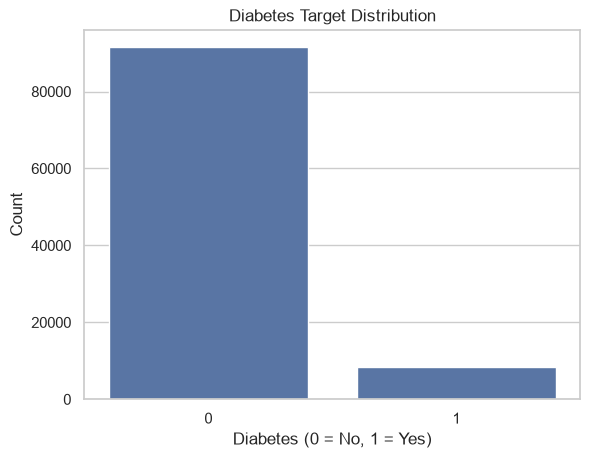

In [23]:
targetPercentage = (
    df_raw["diabetes"].value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

display(pd.DataFrame({
    "counts" : targetCounts,
    "percentage" : targetPercentage
}))

sns.countplot(data = dfRaw, x = "diabetes")
plt.title("Diabetes Target Distribution")
plt.xlabel("Diabetes (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()
    

 as earlier explained by me that there are two features in string.
which are known as categorial values or features. those are
`smoking_history` and `gender`

In [24]:
categorical_cols = ["gender", "smoking_history"]

for col in categorical_cols:
    print(f"\n{col.upper()} distribution:")
    display(df_raw[col].value_counts().to_frame("count"))

    print(f"{col.upper()} diabetes rate:")
    display(
        df_raw.groupby(col)["diabetes"]
        .agg(["count", "mean"])
        .rename(columns={"mean": "diabetes_rate"})
        .sort_values("diabetes_rate", ascending=False)
        .round(3)
    )


GENDER distribution:


,count
gender,
Female,58552
Male,41430
Other,18


GENDER diabetes rate:


,count,diabetes_rate
gender,,
Male,41430,0.097
Female,58552,0.076
Other,18,0.000



SMOKING_HISTORY distribution:


,count
smoking_history,
No Info,35816
never,35095
former,9352
current,9286
not current,6447
ever,4004


SMOKING_HISTORY diabetes rate:


,count,diabetes_rate
smoking_history,,
former,9352,0.170
ever,4004,0.118
not current,6447,0.107
current,9286,0.102
never,35095,0.095
No Info,35816,0.041


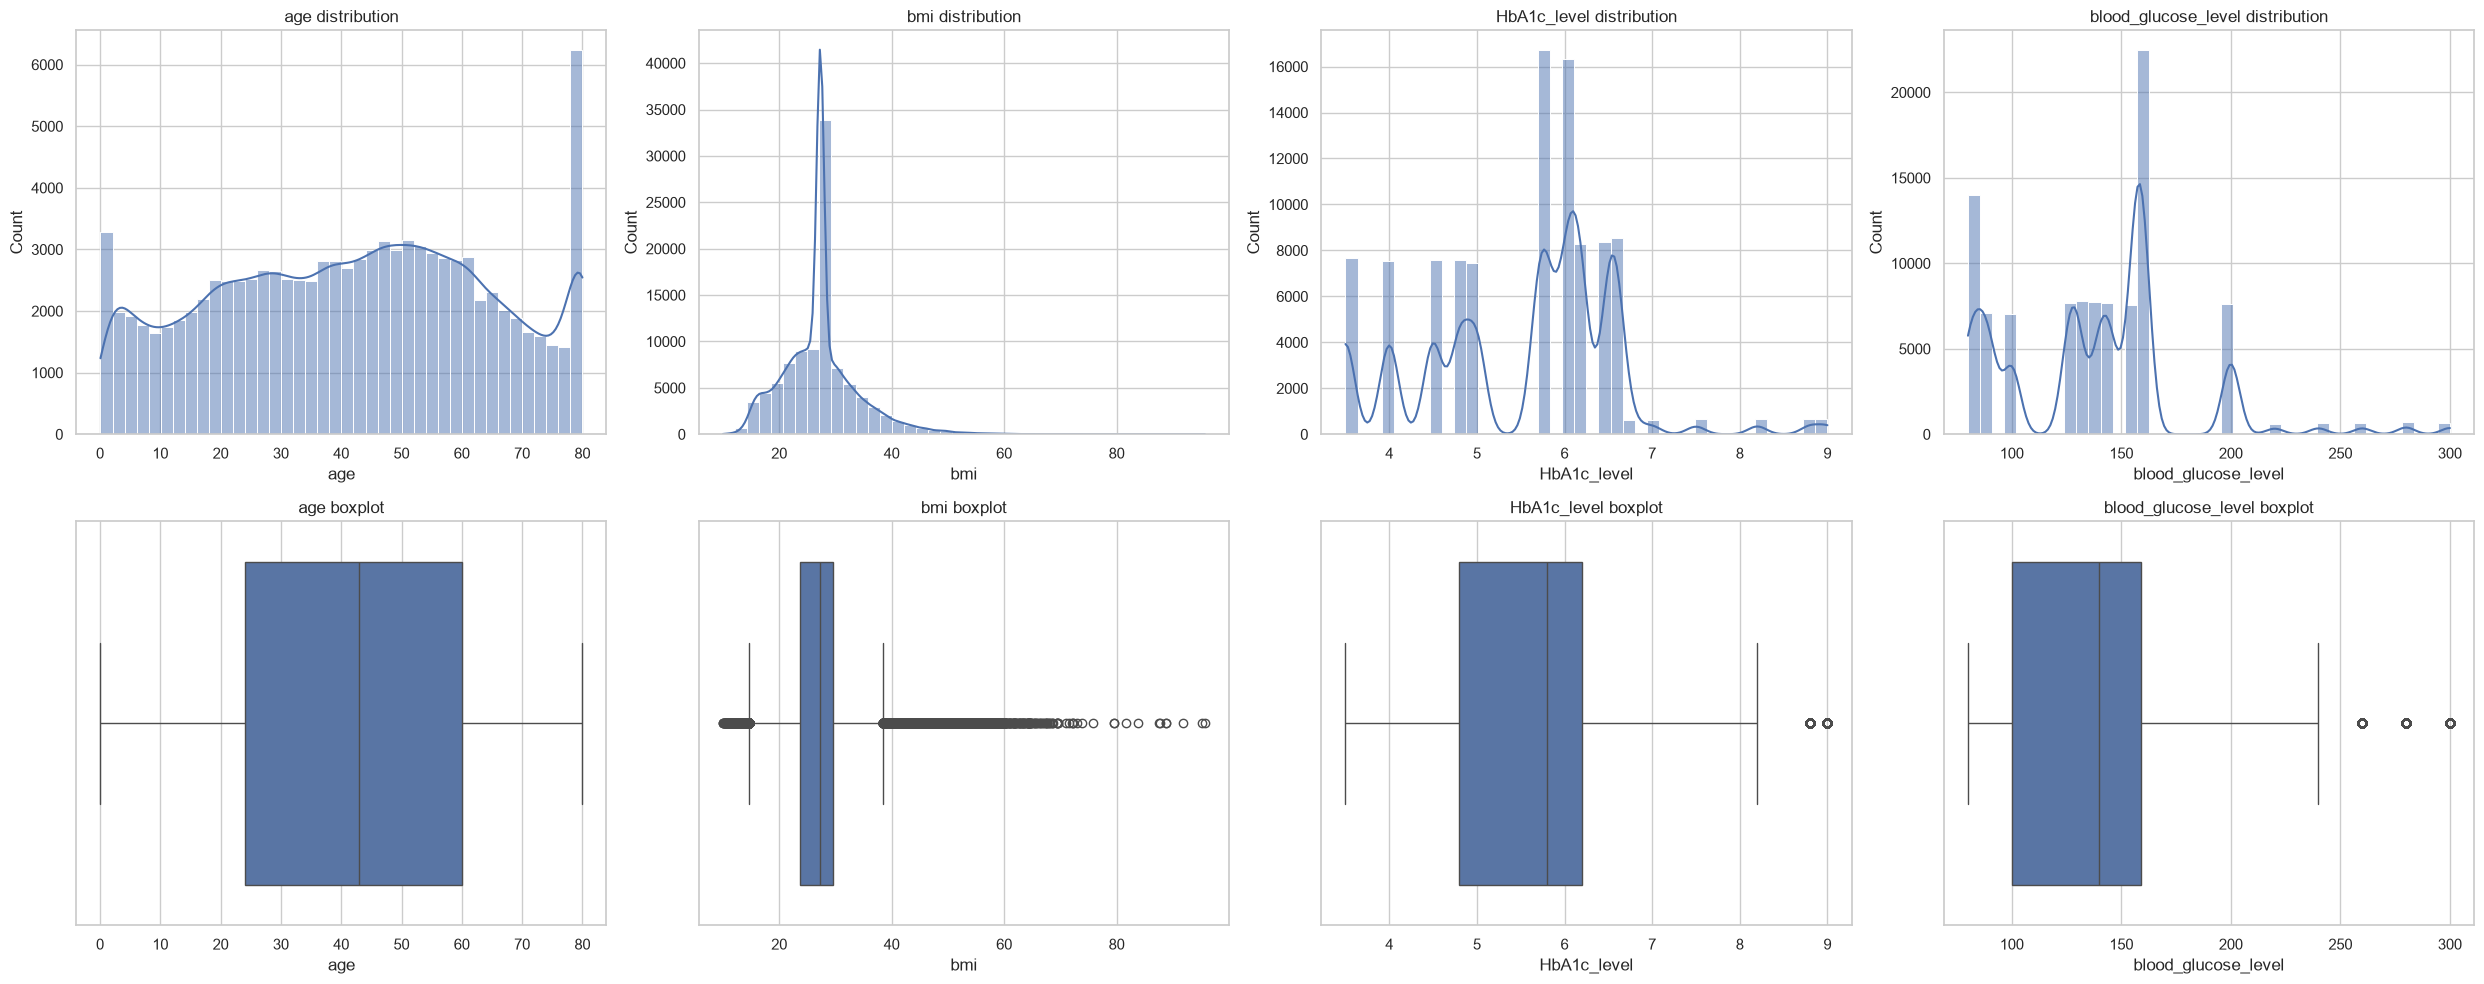

In [31]:
# now let's see the numerical distribution using subplots with box ( for outliers ) 
# and hist for various-ness

numeric_cols = ["age", "bmi", "HbA1c_level", "blood_glucose_level"]

fig, axes = plt.subplots(2,4, figsize=(25,10))

for i, col in enumerate(numeric_cols):
    sns.histplot(data=df_raw, x=col, bins=40, kde=True, ax=axes[0, i])
    axes[0, i].set_title(f"{col} distribution")

    sns.boxplot(data=df_raw, x=col, ax=axes[1, i])
    axes[1, i].set_title(f"{col} boxplot")

plt.tight_layout()
plt.show()

In [33]:
print("Age <= 0:", (df_raw["age"] <= 0).sum())
print("BMI < 10:", (df_raw["bmi"] < 10).sum())
print("BMI > 80:", (df_raw["bmi"] > 80).sum())
print("Gender = Other:", (df_raw["gender"] == "Other").sum())

# the data rules for age and bmi we check it and then clean it

display(df_raw[numeric_cols].quantile([0.01, 0.05, 0.50, 0.95, 0.99]).T)

Age <= 0: 0
BMI < 10: 0
BMI > 80: 9
Gender = Other: 18


,0.01,0.05,0.50,0.95,0.99
age,1.08,4.00,43.00,80.00,80.0000
bmi,14.60,16.82,27.32,39.49,48.7901
HbA1c_level,3.50,3.50,5.80,6.60,8.8000
blood_glucose_level,80.00,80.00,140.00,200.00,280.0000


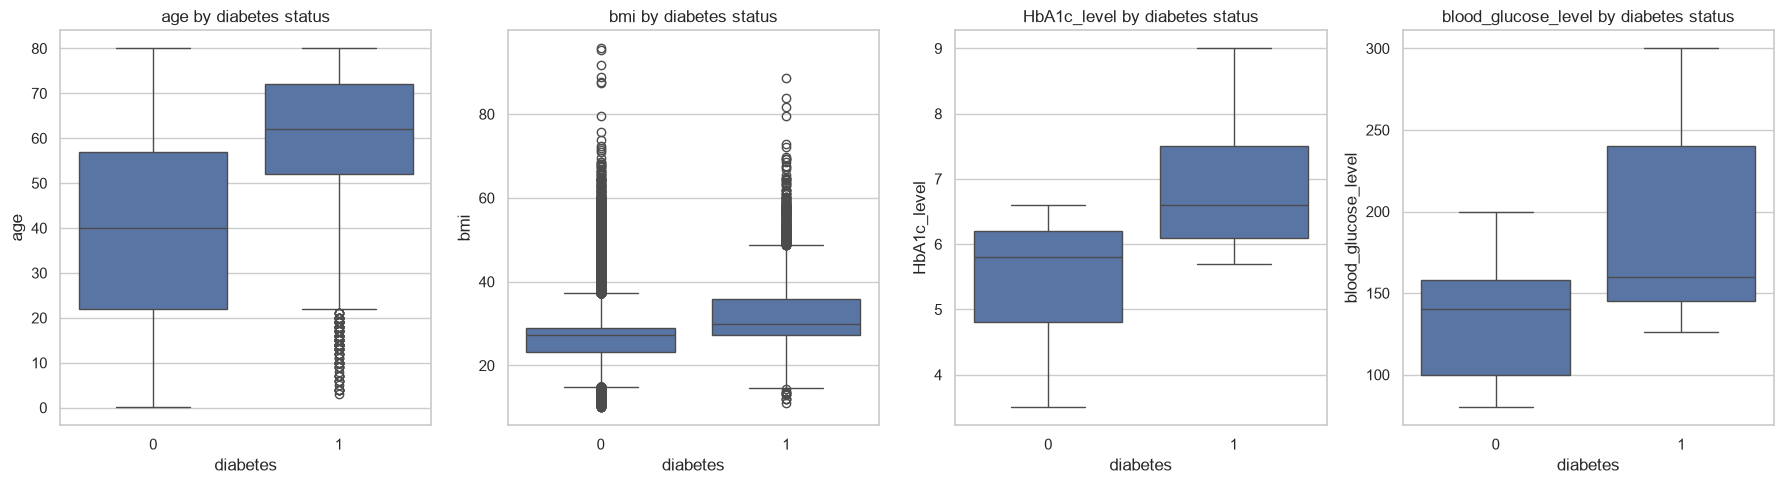

In [34]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for i, col in enumerate(numeric_cols):
    sns.boxplot(data=df_raw, x="diabetes", y=col, ax=axes[i])
    axes[i].set_title(f"{col} by diabetes status")

plt.tight_layout()
plt.show()

Checking the target with numeric values

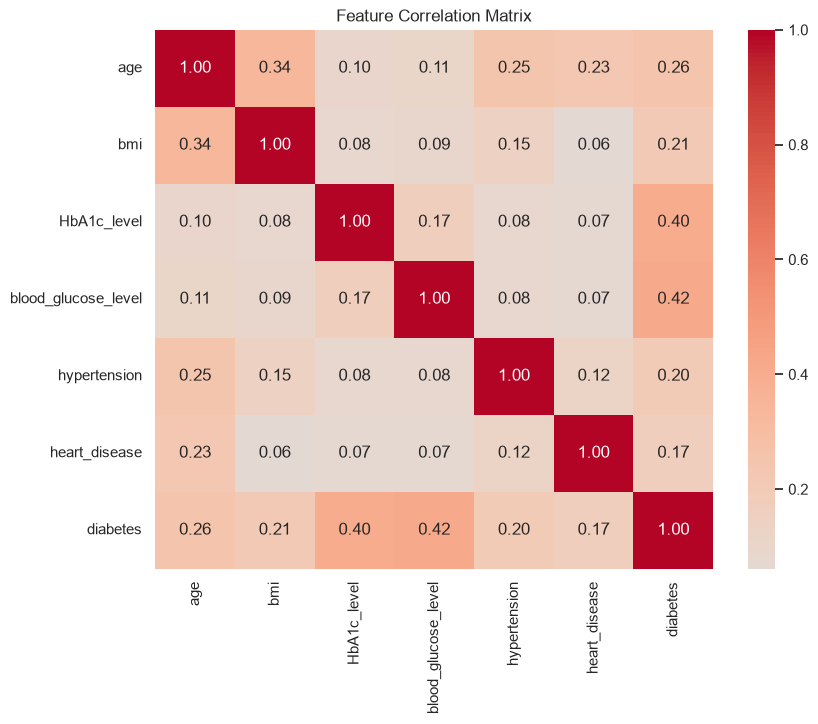

In [36]:
# ofcc we have to check correlation : D

correlation_cols = numeric_cols + ["hypertension", "heart_disease", "diabetes"]

plt.figure(figsize=(9, 7))
sns.heatmap(
    df_raw[correlation_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
)
plt.title("Feature Correlation Matrix")
plt.show()

as exploration and looking at distribution values is done we have to now Clean and Split. 

we already have functions in our preprocessing as `clean_data()` and `split_data()`

In [41]:
df_clean = clean_data(df_raw)     # by preprocessing function

print(f"Rows before cleaning: {len(df_raw):,}")
print(f"Rows after cleaning:  {len(df_clean):,}")
print(f"Rows removed:         {len(df_raw) - len(df_clean):,}")

display(df_clean.head())

Rows before cleaning: 100,000
Rows after cleaning:  96,119
Rows removed:         3,881


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


`100,000` -> `96,119` Rows 

In [42]:
clean_target_summary = (
    df_clean["diabetes"]
    .value_counts()
    .sort_index()
    .to_frame("count")
)

clean_target_summary["percentage"] = (
    df_clean["diabetes"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

display(clean_target_summary)

,count,percentage
diabetes,,
0,87640,91.18
1,8479,8.82


the percentage changes a lot after spliting

In [40]:
X_train, X_test, y_train, y_test = split_data(df_clean)    # by preprocessing function

print("Training features:", X_train.shape)
print("Testing features: ", X_test.shape)
print(f"Training positive rate: {y_train.mean():.4f}")
print(f"Testing positive rate:  {y_test.mean():.4f}")

Training features: (76895, 8)
Testing features:  (19224, 8)
Training positive rate: 0.0882
Testing positive rate:  0.0882


In [43]:
encoder, scaler = fit_preprocessors(X_train, save=True)   # by preprocessing function fitting

X_train_processed = transform(X_train, encoder, scaler)
X_test_processed = transform(X_test, encoder, scaler)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape: ", X_test_processed.shape)

display(X_train_processed.head())

Processed training shape: (76895, 11)
Processed testing shape:  (19224, 11)


,age,bmi,HbA1c_level,blood_glucose_level,gender_Male,smoking_history_current,smoking_history_former,smoking_history_never,smoking_history_not current,hypertension,heart_disease
28331,0.722552,-0.842213,0.899281,0.044642,0.0,1.0,0.0,0.0,0.0,0,0
68751,-1.780520,-1.182612,0.527143,0.533211,0.0,0.0,0.0,0.0,0.0,0,0
46518,-0.435453,0.661461,0.248039,-1.298920,0.0,1.0,0.0,0.0,0.0,0,0
23765,-0.747223,0.429102,-0.496236,1.510347,0.0,0.0,1.0,0.0,0.0,0,0
62969,0.678013,-0.000097,0.620177,0.411069,1.0,0.0,1.0,0.0,0.0,0,0


A Observation the data is way nicely normalize ( standard scaler ) because of this we have healthy data

In [44]:
# final step save the Splitted Data into .csv files
save_split(X_train, X_test, y_train, y_test)

print("Preprocessing complete.")

Preprocessing complete.


#### _Now, as EDA and Preprocessing is done. We can now train the models compare them and Save the Model Picle files. as Comparative Analysis is gonna be in backend-frontend onDemand by user. backend will handle rest._

In [56]:
import os
import joblib

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

## for experimentating 
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import GradientBoostingClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

In [46]:
# We recall the Saved .csv train and test datasets

from preprocessing import load_split

X_train, X_test, y_train, y_test = load_split()

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (76895, 11)
Testing data: (19224, 11)


In [49]:


"""
Let's create a Evaluation function that will be used as a layer of abstraction
between model's ( LR , KNN etc ) and Their trained scores

returns Score Map
with
: Model Name
: Accuracy
: Precision
: Recall
: F1 Score
: ROC-AUC
"""

def evaluate_model(name, model, X_test, y_test):
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    scores = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
    }

    print(f"\n{name}")
    print("-" * len(name))
    print(classification_report(y_test, predictions))

    ConfusionMatrixDisplay.from_predictions(y_test, predictions)
    plt.title(f"{name} Confusion Matrix")
    plt.show()

    print("Accuracy:", scores["Accuracy"]) # gotta add this s

    return scores

### Logistic Regression 
This is the first model with Class Weight Balanced and Max Iteration set to 1000


Logistic Regression
-------------------
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17528
           1       0.43      0.88      0.57      1696

    accuracy                           0.89     19224
   macro avg       0.71      0.88      0.75     19224
weighted avg       0.94      0.89      0.90     19224



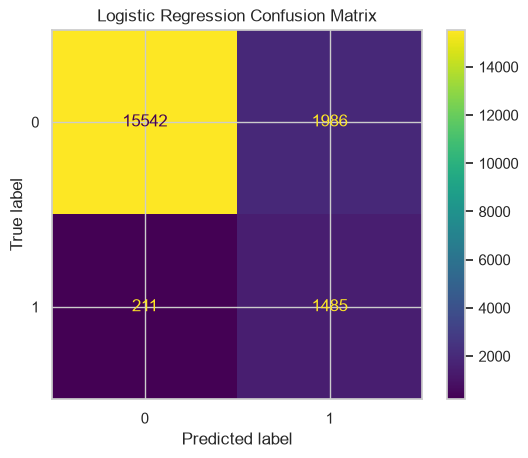

Accuracy: 0.885715771951727


In [50]:
lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42,
)

lr_model.fit(X_train, y_train)
lr_results = evaluate_model("Logistic Regression", lr_model, X_test, y_test)

#### K-Nearest Neighbours
: D


KNN
---
              precision    recall  f1-score   support

           0       0.96      0.99      0.98     17528
           1       0.85      0.62      0.72      1696

    accuracy                           0.96     19224
   macro avg       0.91      0.80      0.85     19224
weighted avg       0.95      0.96      0.95     19224



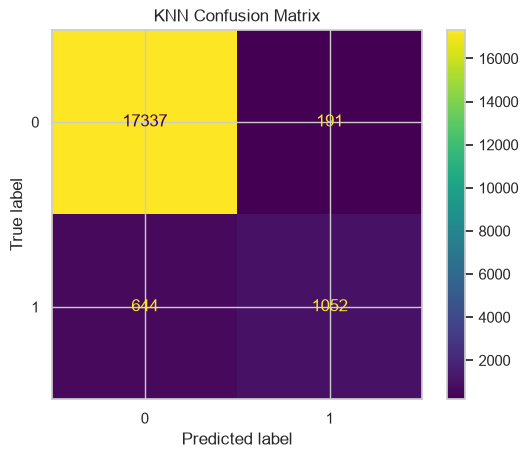

Accuracy: 0.9565647107781939


In [51]:
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    weights="distance",
    n_jobs=-1,
)

knn_model.fit(X_train, y_train)
knn_results = evaluate_model("KNN", knn_model, X_test, y_test)

#### Decision Trees
( cool stuff ) maybe


Decision Tree
-------------
              precision    recall  f1-score   support

           0       0.99      0.90      0.94     17528
           1       0.45      0.89      0.60      1696

    accuracy                           0.90     19224
   macro avg       0.72      0.89      0.77     19224
weighted avg       0.94      0.90      0.91     19224



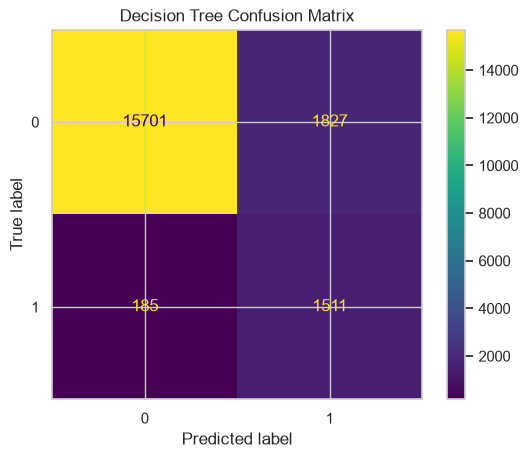

Accuracy: 0.8953391593841032


In [52]:
dt_model = DecisionTreeClassifier(
    max_depth=12,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42,
)

dt_model.fit(X_train, y_train)
dt_results = evaluate_model("Decision Tree", dt_model, X_test, y_test)

#### Random Forest 
lastly it's the best with balanced weight, 200 estimators, 16 would be max depth
along with all cores running


Random Forest
-------------
              precision    recall  f1-score   support

           0       0.99      0.91      0.95     17528
           1       0.50      0.90      0.64      1696

    accuracy                           0.91     19224
   macro avg       0.75      0.91      0.80     19224
weighted avg       0.95      0.91      0.92     19224



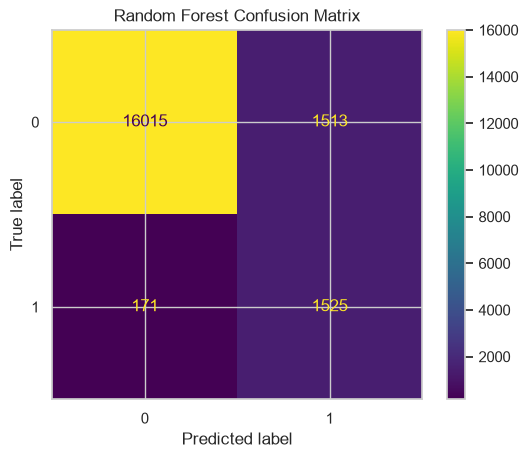

Accuracy: 0.912401165210154


In [53]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=16,
    min_samples_split=20,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)

rf_model.fit(X_train, y_train)
rf_results = evaluate_model("Random Forest", rf_model, X_test, y_test)

In [54]:
"""
Comparing the Models Scores Now
"""

results_df = pd.DataFrame([
    lr_results,
    knn_results,
    dt_results,
    rf_results,
]).sort_values("F1 Score", ascending=False)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
1,KNN,0.9566,0.8463,0.6203,0.7159,0.9010
3,Random Forest,0.9124,0.5020,0.8992,0.6443,0.9760
2,Decision Tree,0.8953,0.4527,0.8909,0.6003,0.9641
0,Logistic Regression,0.8857,0.4278,0.8756,0.5748,0.9609


Experiment Cells ~ May get merge with main codebase

#### Naive Bayes



Gaussian Naive Bayes
--------------------
              precision    recall  f1-score   support

           0       0.96      0.92      0.94     17528
           1       0.45      0.64      0.53      1696

    accuracy                           0.90     19224
   macro avg       0.71      0.78      0.74     19224
weighted avg       0.92      0.90      0.91     19224



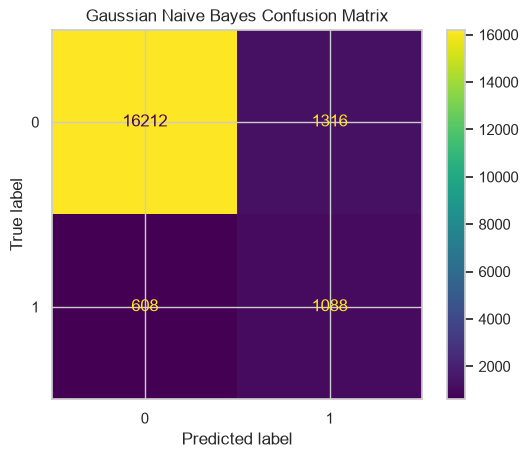

Accuracy: 0.8999167707032876


In [57]:
nb_model = GaussianNB()

nb_model.fit(X_train, y_train)
nb_results = evaluate_model("Gaussian Naive Bayes", nb_model, X_test, y_test)

#### Gradient Boosting



Gradient Boosting
-----------------
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17528
           1       0.98      0.67      0.80      1696

    accuracy                           0.97     19224
   macro avg       0.98      0.83      0.89     19224
weighted avg       0.97      0.97      0.97     19224



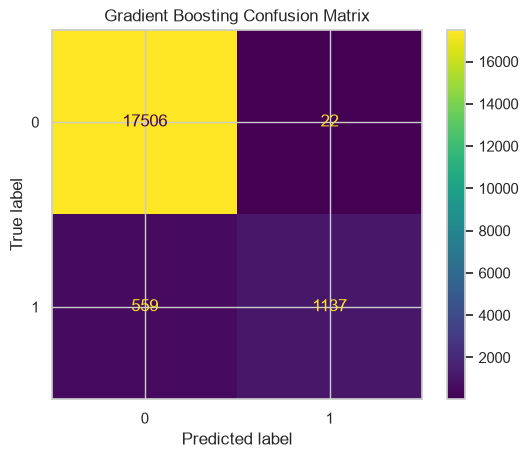

Accuracy: 0.9697773616312942


In [58]:
gb_model = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=4,
    min_samples_leaf=10,
    random_state=42,
)

gb_model.fit(X_train, y_train)
gb_results = evaluate_model("Gradient Boosting", gb_model, X_test, y_test)

#### XG Boost 
Hopes are up for this one

In [59]:
negative_cases = (y_train == 0).sum()
positive_cases = (y_train == 1).sum()
scale_pos_weight = negative_cases / positive_cases

print("scale_pos_weight:", round(scale_pos_weight, 2))

scale_pos_weight: 10.34



XGBoost
-------
              precision    recall  f1-score   support

           0       0.99      0.90      0.94     17528
           1       0.48      0.92      0.63      1696

    accuracy                           0.90     19224
   macro avg       0.73      0.91      0.79     19224
weighted avg       0.95      0.90      0.92     19224



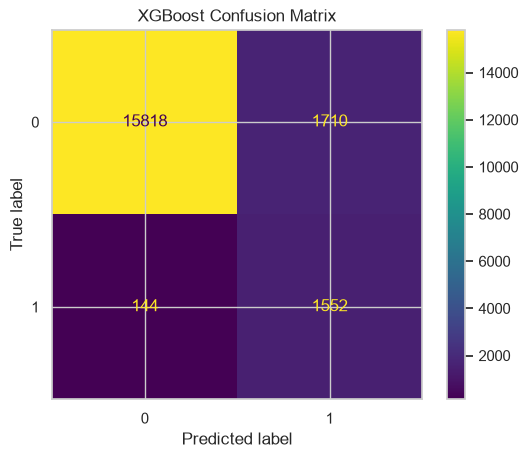

Accuracy: 0.903558052434457


In [60]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
)

xgb_model.fit(X_train, y_train)
xgb_results = evaluate_model("XGBoost", xgb_model, X_test, y_test)

#### SVM 


In [61]:
X_svm_train, _, y_svm_train, _ = train_test_split(
    X_train,
    y_train,
    train_size=10000,
    stratify=y_train,
    random_state=42,
)

print("SVM training subset:", X_svm_train.shape)

SVM training subset: (10000, 11)


C:\Users\Yash\AppData\Roaming\Python\Python313\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



RBF SVM (10k training subset)
-----------------------------
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17528
           1       0.45      0.90      0.60      1696

    accuracy                           0.90     19224
   macro avg       0.72      0.90      0.77     19224
weighted avg       0.94      0.90      0.91     19224



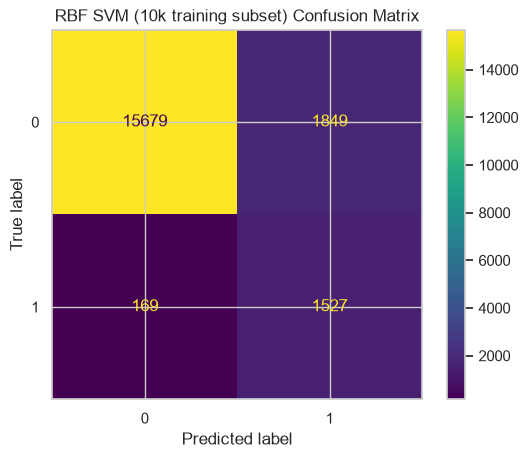

Accuracy: 0.8950270495214315


In [63]:
svm_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    class_weight="balanced",
    probability=True,
    random_state=42,
)

svm_model.fit(X_svm_train, y_svm_train)
svm_results = evaluate_model("RBF SVM (10k training subset)", svm_model, X_test, y_test)

#### Voting Classifier 


Soft Voting Classifier
----------------------
              precision    recall  f1-score   support

           0       0.98      0.96      0.97     17528
           1       0.65      0.82      0.73      1696

    accuracy                           0.95     19224
   macro avg       0.82      0.89      0.85     19224
weighted avg       0.95      0.95      0.95     19224



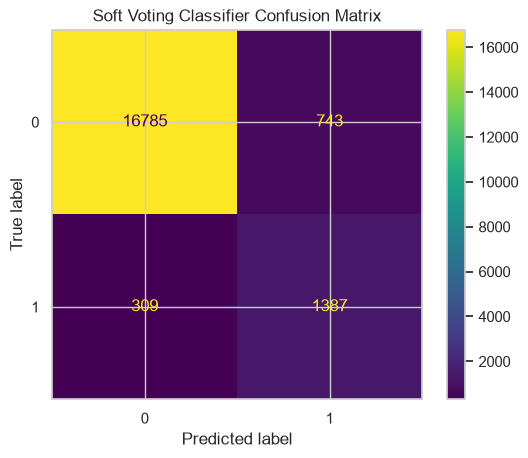

Accuracy: 0.9452767374115689


In [64]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", lr_model),
        ("knn", knn_model),
        ("dt", dt_model),
        ("rf", rf_model),
        ("gb", gb_model),
        ("xgb", xgb_model),
    ],
    voting="soft",
    weights=[1, 1, 1, 2, 2, 2],
    n_jobs=-1,
)

voting_model.fit(X_train, y_train)
voting_results = evaluate_model("Soft Voting Classifier", voting_model, X_test, y_test)


RBF SVM (10k training subset)
-----------------------------
              precision    recall  f1-score   support

           0       0.97      0.98      0.97     17528
           1       0.75      0.64      0.69      1696

    accuracy                           0.95     19224
   macro avg       0.86      0.81      0.83     19224
weighted avg       0.95      0.95      0.95     19224



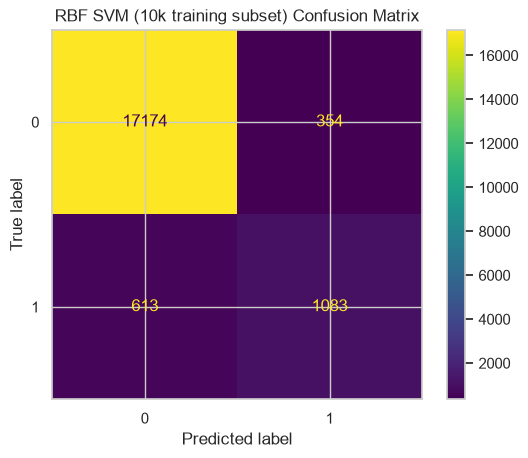

Accuracy: 0.9496982937994174


In [67]:
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV

svm_base = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    class_weight="balanced",
    random_state=42,
)

svm_model = CalibratedClassifierCV(
    estimator=svm_base,
    method="sigmoid",
    cv=3,
    ensemble=False,
    n_jobs=-1,
)

svm_model.fit(X_svm_train, y_svm_train)
svm_results = evaluate_model(
    "RBF SVM (10k training subset)",
    svm_model,
    X_test,
    y_test,
)

In [65]:
results_df = pd.DataFrame([
    lr_results,
    knn_results,
    dt_results,
    rf_results,
    nb_results,
    gb_results,
    xgb_results,
    svm_results,
    voting_results,
]).sort_values("F1 Score", ascending=False)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
5,Gradient Boosting,0.9698,0.9810,0.6704,0.7965,0.9773
8,Soft Voting Classifier,0.9453,0.6512,0.8178,0.7250,0.9762
1,KNN,0.9566,0.8463,0.6203,0.7159,0.9010
3,Random Forest,0.9124,0.5020,0.8992,0.6443,0.9760
6,XGBoost,0.9036,0.4758,0.9151,0.6261,0.9779
7,RBF SVM (10k training subset),0.8950,0.4523,0.9004,0.6021,0.9628
2,Decision Tree,0.8953,0.4527,0.8909,0.6003,0.9641
0,Logistic Regression,0.8857,0.4278,0.8756,0.5748,0.9609
4,Gaussian Naive Bayes,0.8999,0.4526,0.6415,0.5307,0.9155


In [66]:
joblib.dump(nb_model, "models/model_nb.pkl")
joblib.dump(gb_model, "models/model_gb.pkl")
joblib.dump(xgb_model, "models/model_xgb.pkl")
joblib.dump(svm_model, "models/model_svm.pkl")
joblib.dump(voting_model, "models/model_voting.pkl")

['models/model_voting.pkl']